# 04 — Time Series Analysis (thesis Chapter 5)

**Input:** `data/processed/monthly_data.csv` (statewide monthly totals, 2013–2022; see `docs/data_dictionary.md`).

| Thesis item | Output |
|---|---|
| Fig 5.1 time series of predictors | `figures/ts.pdf` |
| Fig 5.2 wildfire vs prescribed time series | `figures/rx_wild_ts.pdf` |
| Fig 5.3 correlation matrix | `figures/correlation_mat.pdf` |
| Fig 5.4 / Table 5.1 cross-correlation with log wildfire acres | `figures/cross_correlation.pdf`, printed LaTeX |

# Time Series Analysis

In [1]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import numpy as np 
import matplotlib.dates as mdates
import seaborn as sn
import os
import datetime
import xarray as xr
import rioxarray
from math import comb, log
plt.style.use("ggplot")
import statsmodels.api as sm
from functions import *

In [2]:
data = pd.read_csv("data/processed/monthly_data.csv", index_col=0)

In [3]:
data

,rx_acres,rx_acres_3_month,rx_acres_6_month,rx_acres_9_month,rx_acres_12_month,incident_acres_burned,cdd,hdd,pcp,pdsi,phdi,pmdi,tavg,tmax,tmin,zndx
2013-01-31 00:00:00+00:00,548.078092,8494.236071,11597.795940,15273.78719,17490.87933,0,0,576,1.19,-0.80,-0.80,-0.80,42.1,53.2,31.0,-2.39
2013-02-28 00:00:00+00:00,319.037923,8494.236071,8570.236071,14849.94974,17091.93358,407,0,476,0.58,-1.66,-1.66,-1.66,45.3,57.6,33.1,-2.84
2013-03-31 00:00:00+00:00,403.706443,7236.576912,9361.352086,14621.07384,16361.41022,0,8,317,1.33,-2.43,-2.43,-2.43,53.8,66.5,41.0,-2.84
2013-04-30 00:00:00+00:00,1892.390845,2613.074676,9361.352086,12464.91196,16140.90321,379,22,219,0.71,-2.83,-2.83,-2.83,58.2,71.7,44.7,-1.95
2013-05-31 00:00:00+00:00,2108.507682,3163.213302,11657.449370,11733.44937,18013.16304,54916,63,112,0.62,-2.98,-2.98,-2.98,63.8,77.5,50.1,-1.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-08-31 00:00:00+00:00,15.000000,11297.365690,23227.702390,35863.81239,36765.01239,31789,340,0,0.40,-4.78,-4.78,-4.78,78.4,92.9,64.0,-0.41
2022-09-30 00:00:00+00:00,1327.228941,10166.571040,18087.909940,29206.40239,36740.71239,131059,271,3,0.83,-4.04,-4.04,-3.70,73.8,87.6,60.1,0.75
2022-10-31 00:00:00+00:00,11740.186050,7086.969981,14552.246750,26023.88133,37846.94133,50,63,86,0.16,-4.49,-4.49,-4.49,63.7,77.6,49.7,-2.61
2022-11-30 00:00:00+00:00,1984.361678,1435.028941,12639.594630,24569.93133,37206.04133,0,0,431,2.00,-4.24,-4.24,-4.24,46.8,58.4,35.2,-0.63


In [4]:
data.index = pd.to_datetime(data.index)

In [5]:
data.columns

Index(['rx_acres', 'rx_acres_3_month', 'rx_acres_6_month', 'rx_acres_9_month',
       'rx_acres_12_month', 'incident_acres_burned', 'cdd', 'hdd', 'pcp',
       'pdsi', 'phdi', 'pmdi', 'tavg', 'tmax', 'tmin', 'zndx'],
      dtype='object')

# Monthly Analysis

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(data['incident_acres_burned'], color='black', label='Wildland Fire')
ax1.plot(data["rx_acres"], color='red', label='Prescribed Fire')
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.set_title("Monthly Time Series of Total Fire Acerage")
ax1.legend()
ax1.tick_params(axis='x', labelrotation=90)
ax1.set_yscale('log')
ax1.set_ylabel('Monthly Total Acres')

ax2.plot(data['incident_acres_burned'], color='black', label='Wildland Fire')
ax2.plot(data["rx_acres"], color='red', label='Prescribed Fire')
ax2.xaxis.set_major_locator(mdates.YearLocator()) # check the axis - might be incorrect
ax2.set_title("Monthly Time Series of Total Fire Acerage")
ax2.legend()
ax2.tick_params(axis='x', labelrotation=90)
ax2.set_ylabel('Monthly Total Acres') # power spectrum
plt.tight_layout()
plt.savefig("figures/rx_wild_ts.pdf")
plt.show()

<Figure size 1200x400 with 2 Axes>

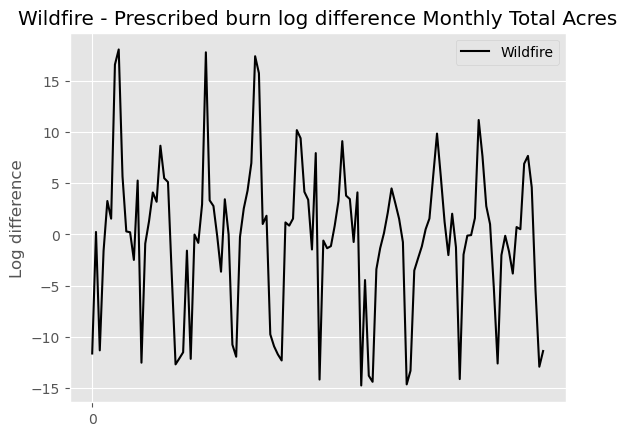

In [7]:
fig, ax = plt.subplots()
l1 = np.array([log(i+0.005) for i in data['incident_acres_burned'].tolist()])
l2 = np.array([log(j+0.005) for j in data["rx_acres"].tolist()])
log_diff = np.subtract(l1, l2)
ax.plot([i for i in range(len(log_diff))], log_diff, color='black', label='Wildfire')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.set_title("Wildfire - Prescribed burn log difference Monthly Total Acres")
ax.legend()
#ax.set_yscale('log')
ax.set_ylabel('Log difference')
plt.show()

## Time Series of Single Variables

/Users/sequo/Desktop/Academics/masters/thesis/functions.py:408: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[curr_row, curr_col].set_xticklabels(ax[curr_row, curr_col].get_xticklabels(), rotation=75)
/Users/sequo/Desktop/Academics/masters/thesis/functions.py:408: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[curr_row, curr_col].set_xticklabels(ax[curr_row, curr_col].get_xticklabels(), rotation=75)
/Users/sequo/Desktop/Academics/masters/thesis/functions.py:408: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[curr_row, curr_col].set_xticklabels(ax[curr_row, curr_col].get_xticklabels(), rotation=75)
/Users/sequo/Desktop/Academics/masters/thesis/functions.py:408: UserWarning: set_ticklabels() should only be used with a fixed number of

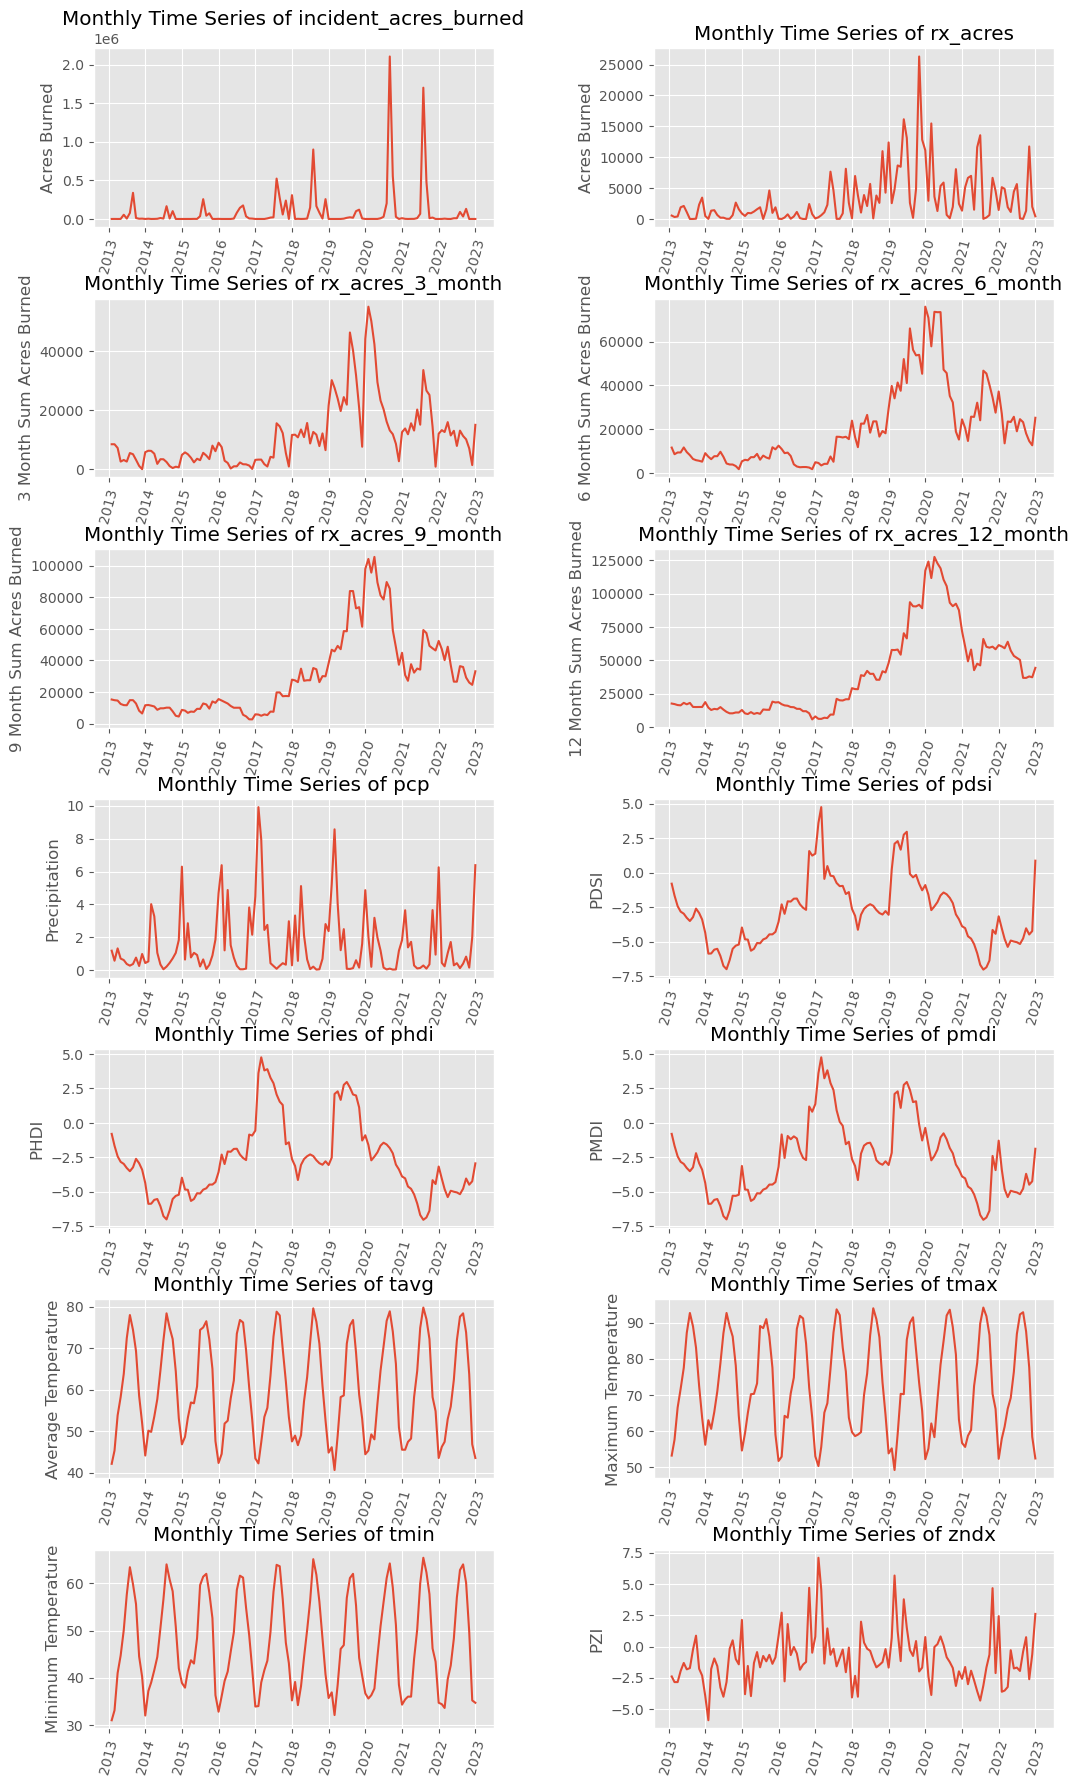

In [8]:
ylabs = ["Acres Burned", "Acres Burned", "3 Month Sum Acres Burned", "6 Month Sum Acres Burned",
         "9 Month Sum Acres Burned", "12 Month Sum Acres Burned",  "Precipitation",
         "PDSI",  "PHDI",  "PMDI", 
         "Average Temperature", "Maximum Temperature", "Minimum Temperature", "PZI"]
logs = [False] +[False for i in range(1, len(ylabs))]
cols = ["incident_acres_burned"]+[col for col in data.columns if col!="incident_acres_burned"]
cols.remove('hdd')
cols.remove('cdd')
ts = graph_timeseries(data, cols, logs, ylabs)
ts.tight_layout()
ts.savefig("figures/ts.pdf")

## Auto Correlation

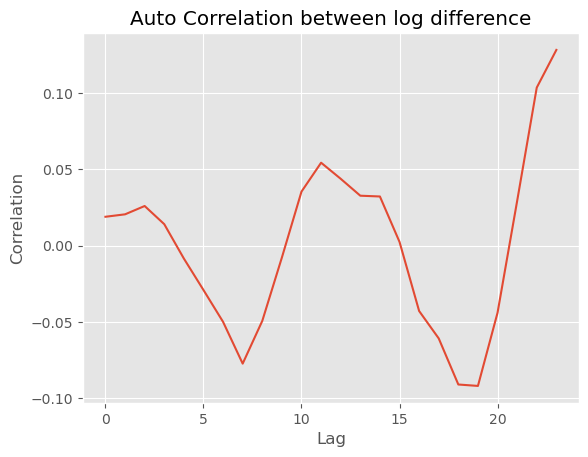

In [9]:
corr = sm.tsa.stattools.ccf(log_diff, log_diff, adjusted=False)

# Remove padding and reverse the order
corrs = corr[0:(len(log_diff)+1)][::-1][:24]
plt.plot(corrs)
plt.xlabel("Lag")
plt.ylabel("Correlation")
plt.title("Auto Correlation between log difference") # not much auto correlation
plt.show()

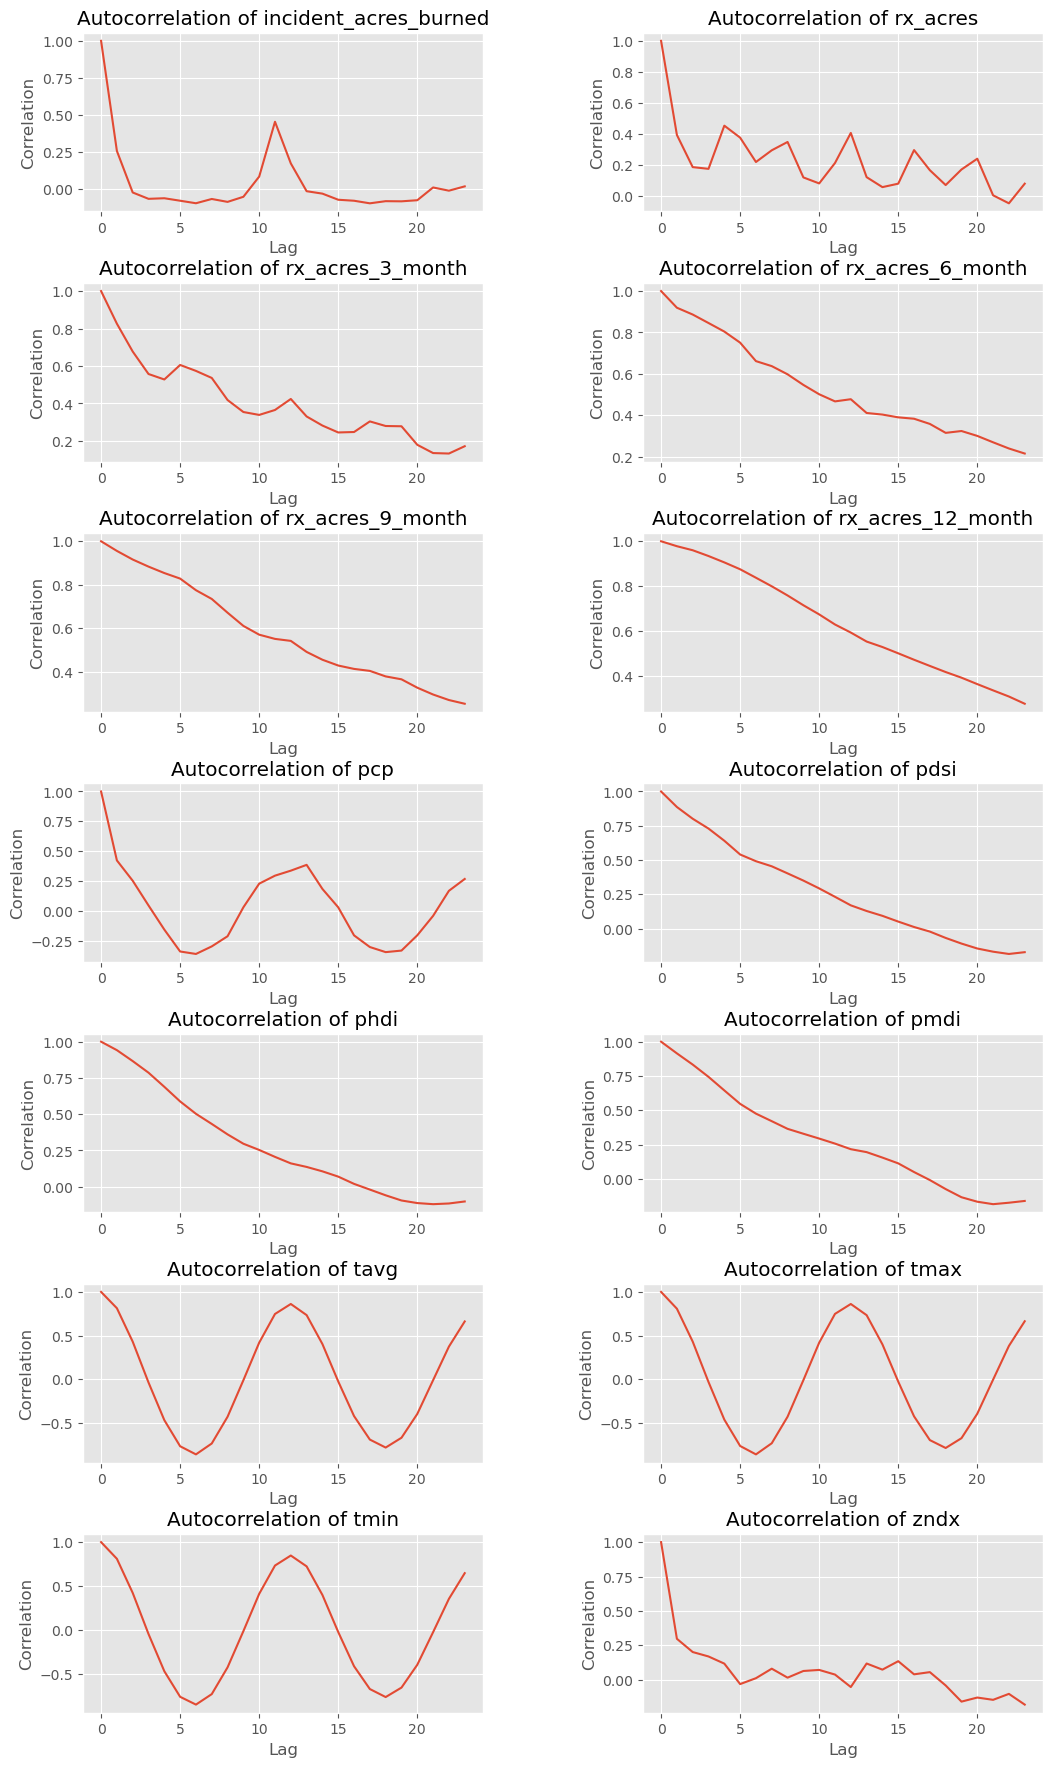

,incident_acres_burned,rx_acres,rx_acres_3_month,rx_acres_6_month,rx_acres_9_month,rx_acres_12_month,pcp,pdsi,phdi,pmdi,tavg,tmax,tmin,zndx
best lag,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.000
min R,-0.099,-0.049,0.132,0.215,0.252,0.274,-0.363,-0.185,-0.12,-0.185,-0.862,-0.861,-0.848,-0.181
max R,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.00,1.000,1.000,1.000,1.000,1.000


In [10]:
_, df = autocorrelations(data, cols)
df

## Cross Correlation

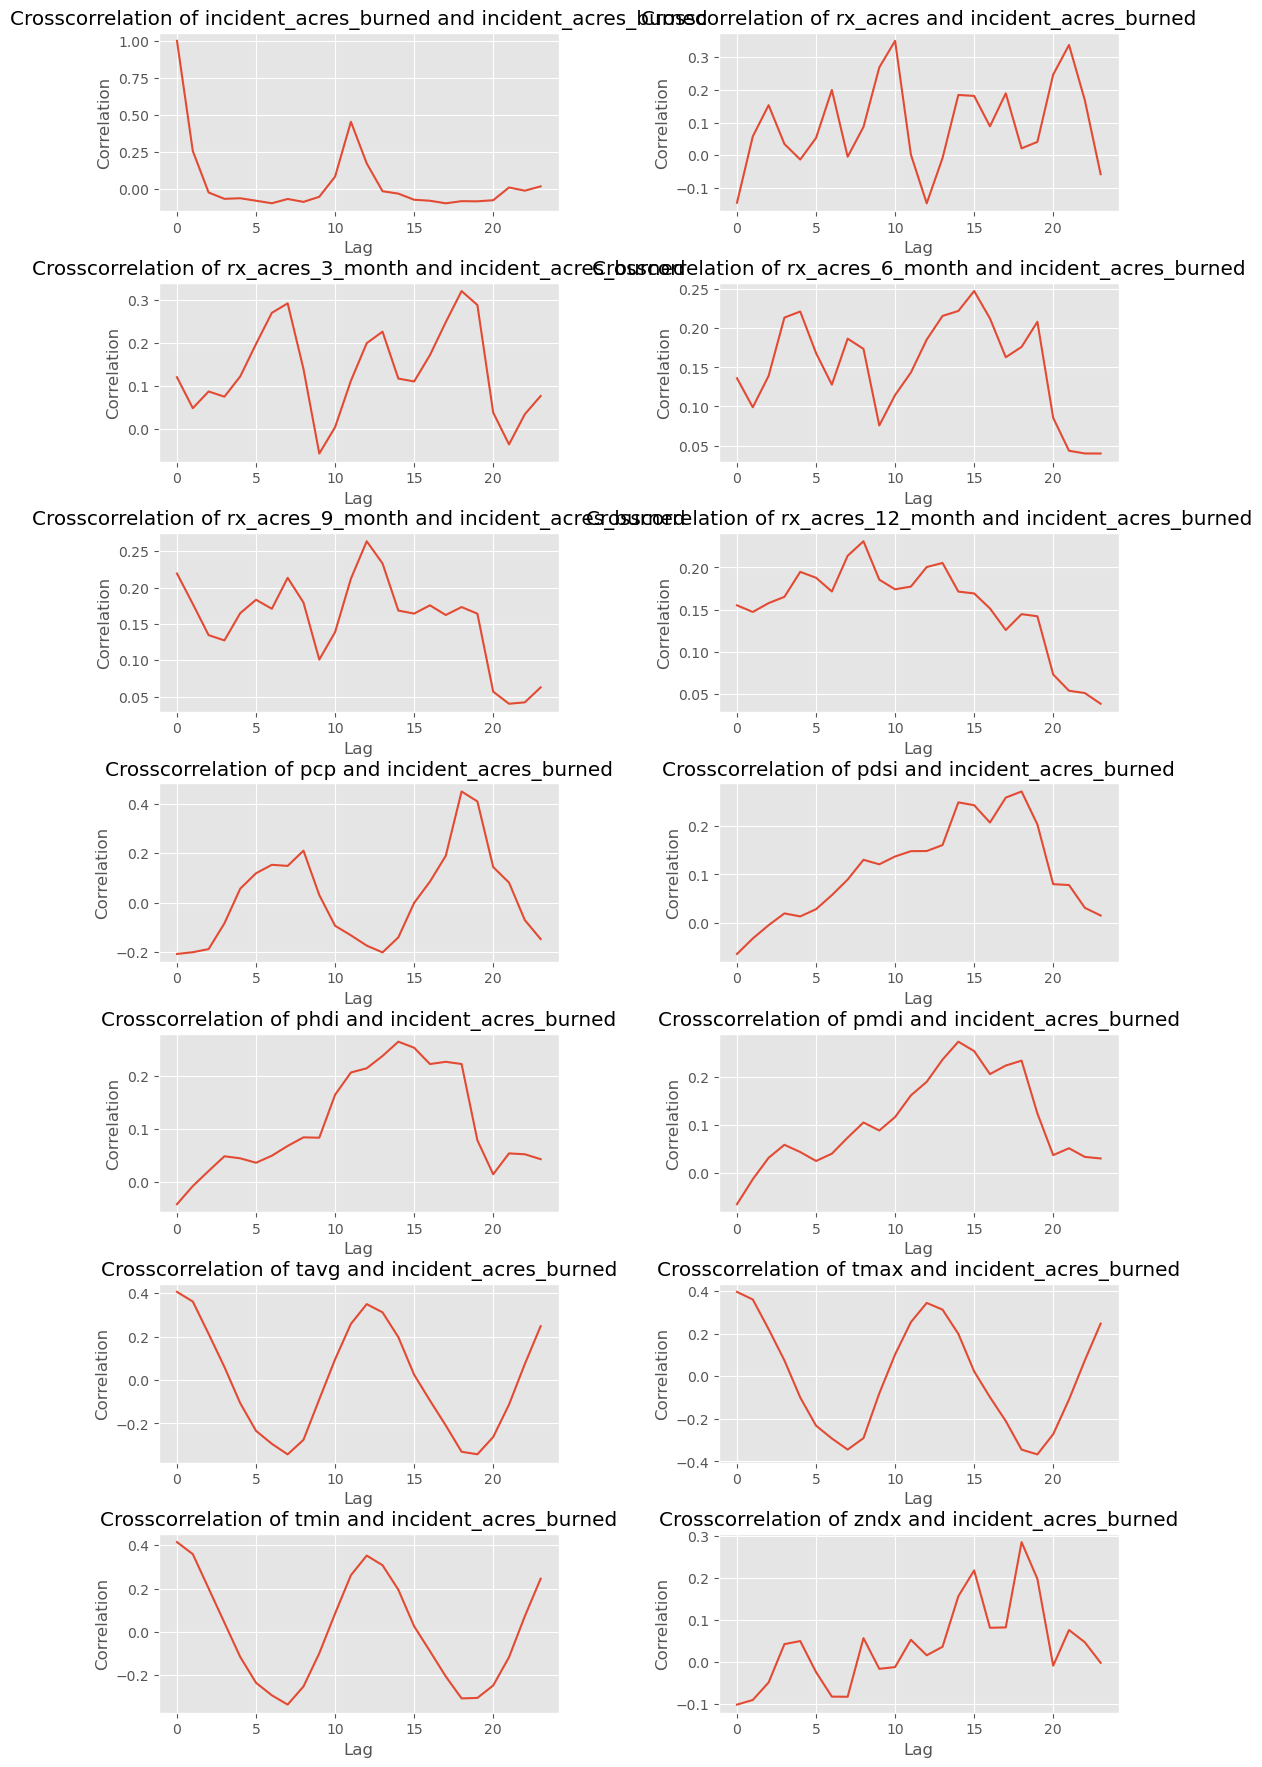

"\\begin{tabular}{lrrr}\n\\toprule\n & best lag & min R & max R \\\\\n\\midrule\n('incident_acres_burned', 'incident_acres_burned') & 0.000000 & -0.099000 & 1.000000 \\\\\n('rx_acres', 'incident_acres_burned') & 10.000000 & -0.147000 & 0.350000 \\\\\n('rx_acres_3_month', 'incident_acres_burned') & 18.000000 & -0.057000 & 0.322000 \\\\\n('rx_acres_6_month', 'incident_acres_burned') & 15.000000 & 0.040000 & 0.248000 \\\\\n('rx_acres_9_month', 'incident_acres_burned') & 12.000000 & 0.040000 & 0.264000 \\\\\n('rx_acres_12_month', 'incident_acres_burned') & 8.000000 & 0.039000 & 0.231000 \\\\\n('pcp', 'incident_acres_burned') & 18.000000 & -0.209000 & 0.451000 \\\\\n('pdsi', 'incident_acres_burned') & 18.000000 & -0.064000 & 0.271000 \\\\\n('phdi', 'incident_acres_burned') & 14.000000 & -0.041000 & 0.265000 \\\\\n('pmdi', 'incident_acres_burned') & 14.000000 & -0.065000 & 0.274000 \\\\\n('tavg', 'incident_acres_burned') & 0.000000 & -0.342000 & 0.406000 \\\\\n('tmax', 'incident_acres_burned

In [11]:
_, res = crosscorrelations_target(data, cols, "incident_acres_burned")
res.T.to_latex()

# Annual Analysis: Pearson R correlation

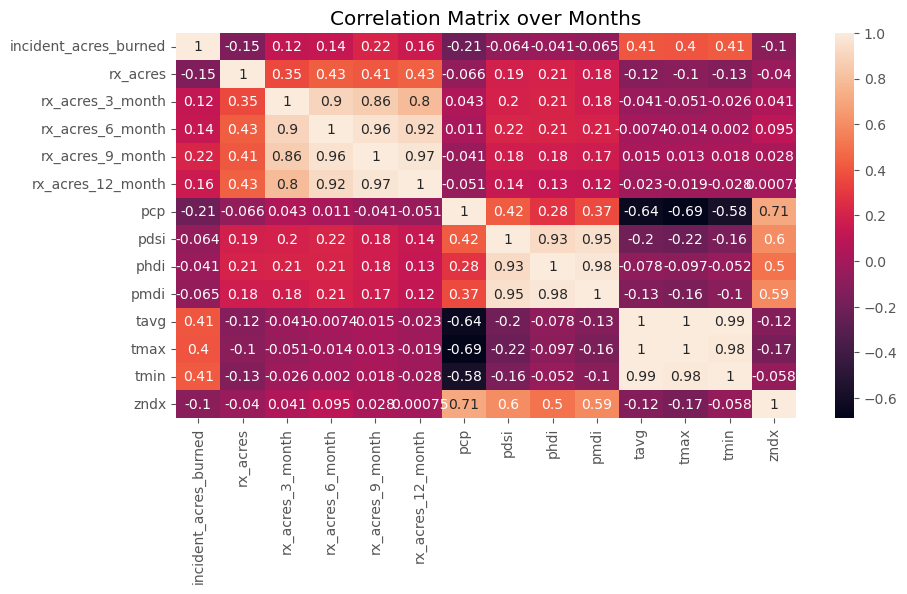

In [12]:
corr_matrix = data[cols].corr()
plt.figure(figsize=(10,5))
sn.heatmap(corr_matrix, annot=True)
plt.title("Correlation Matrix over Months")
plt.show()

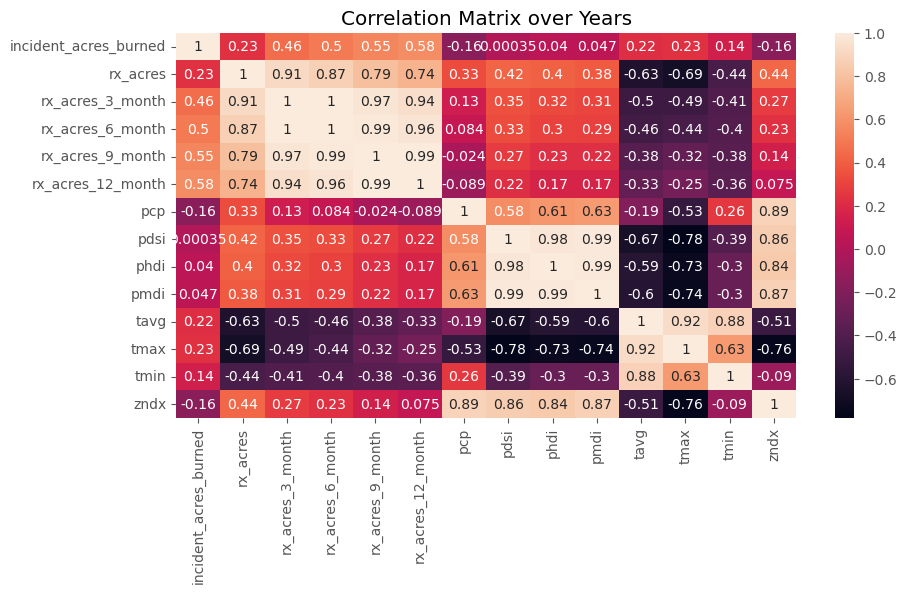

In [13]:
# could do for frequency
annual = data[cols].resample('Y').sum()
corr_matrix = annual.corr()
plt.figure(figsize=(10,5))
sn.heatmap(corr_matrix, annot=True)
plt.title("Correlation Matrix over Years")
plt.show()

# Log target

In [14]:
data["log_acres"] = np.log(data['incident_acres_burned'].replace(0, np.nan)).replace(np.nan, 0)
cols.remove('incident_acres_burned')
# cols.remove('hdd')
# cols.remove('cdd')
cols =  cols + ["log_acres"]

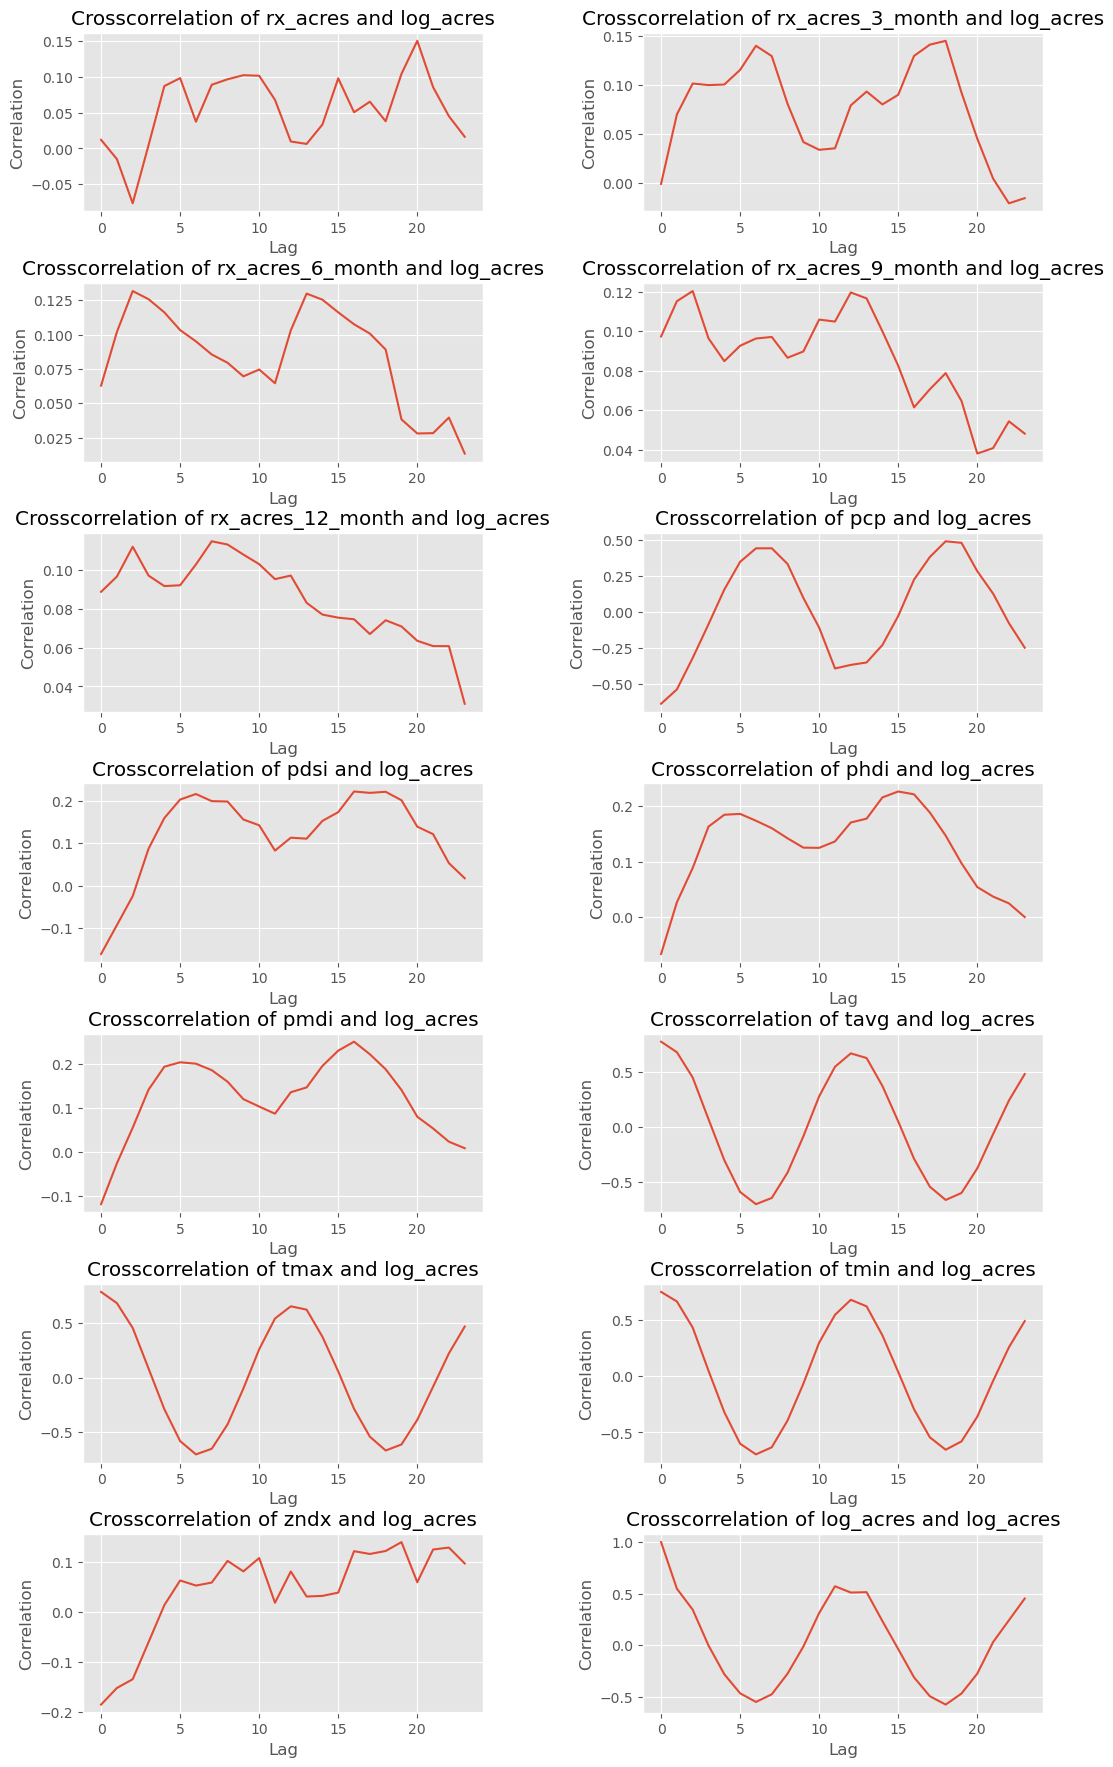

In [15]:
_, res = crosscorrelations_target(data, cols, "log_acres")

In [16]:
import scipy.signal as ss

def ccf(x, y, lag_max = 100):

    result = ss.correlate(y - np.mean(y), x - np.mean(x), method='direct') / (np.std(y) * np.std(x) * len(y))
    length = (len(result) - 1) // 2
    lo = length - lag_max
    hi = length + (lag_max + 1)

    return result[lo:hi]

In [17]:
cols.remove("rx_acres_3_month")
cols.remove("rx_acres_6_month")
cols.remove("rx_acres_9_month")
cols.remove("rx_acres_12_month")

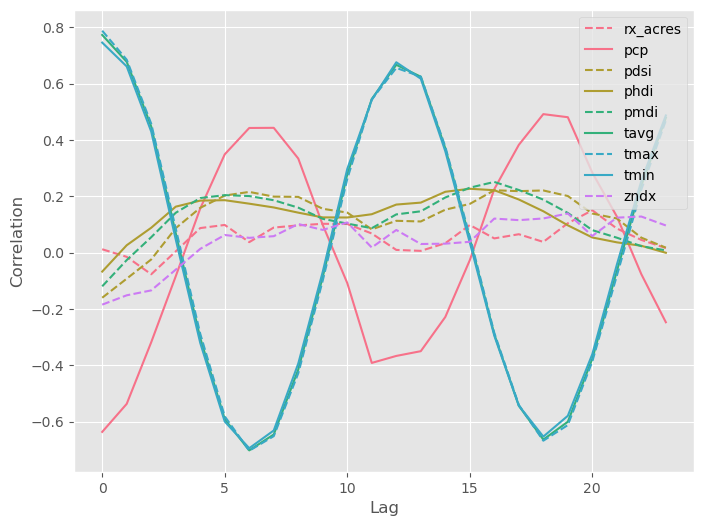

In [18]:
cc, res = crosscorrelations_target_single_plot(data, cols, "log_acres")
cc.tight_layout()
cc.savefig("figures/cross_correlation.pdf")

In [19]:
res

,"(rx_acres, log_acres)","(pcp, log_acres)","(pdsi, log_acres)","(phdi, log_acres)","(pmdi, log_acres)","(tavg, log_acres)","(tmax, log_acres)","(tmin, log_acres)","(zndx, log_acres)"
best pos lag,20.000,18.000,16.000,15.000,16.000,0.000,0.000,0.000,19.000
max R,0.150,0.492,0.222,0.227,0.251,0.773,0.788,0.746,0.139
best neg lag,2.000,0.000,0.000,0.000,0.000,6.000,6.000,6.000,0.000
min R,-0.077,-0.636,-0.160,-0.067,-0.120,-0.702,-0.703,-0.694,-0.185


In [20]:
print(res.T.to_latex())

\begin{tabular}{lrrrr}
\toprule
 & best pos lag & max R & best neg lag & min R \\
\midrule
('rx_acres', 'log_acres') & 20.000000 & 0.150000 & 2.000000 & -0.077000 \\
('pcp', 'log_acres') & 18.000000 & 0.492000 & 0.000000 & -0.636000 \\
('pdsi', 'log_acres') & 16.000000 & 0.222000 & 0.000000 & -0.160000 \\
('phdi', 'log_acres') & 15.000000 & 0.227000 & 0.000000 & -0.067000 \\
('pmdi', 'log_acres') & 16.000000 & 0.251000 & 0.000000 & -0.120000 \\
('tavg', 'log_acres') & 0.000000 & 0.773000 & 6.000000 & -0.702000 \\
('tmax', 'log_acres') & 0.000000 & 0.788000 & 6.000000 & -0.703000 \\
('tmin', 'log_acres') & 0.000000 & 0.746000 & 6.000000 & -0.694000 \\
('zndx', 'log_acres') & 19.000000 & 0.139000 & 0.000000 & -0.185000 \\
\bottomrule
\end{tabular}



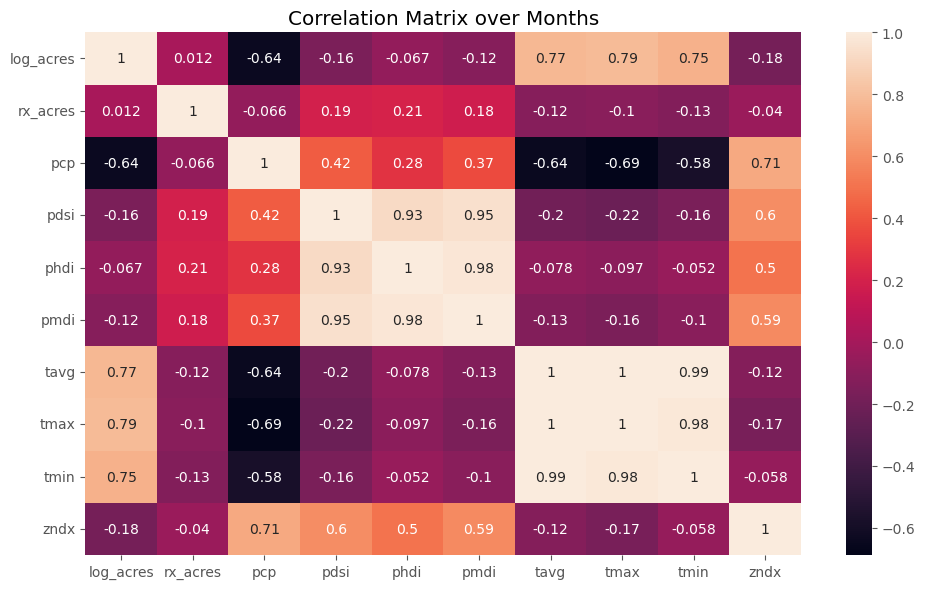

In [21]:
corr_matrix = data[["log_acres"]+cols[:-1]].corr()
plt.figure(figsize=(10,6))
sn.heatmap(corr_matrix, annot=True)
plt.title("Correlation Matrix over Months")
plt.tight_layout()
plt.savefig("figures/correlation_mat.pdf")
plt.show()